# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

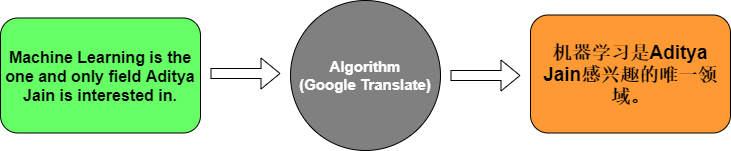

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Task 1 — Answers

1. **Embedding:** Converts each integer word ID into a dense numerical vector. Words can therefore be represented by learned vectors instead of plain numbers.

2. **Encoder LSTM:** Reads the English input sequence and summarizes its information in its hidden state, which is passed to the decoder.

3. **Decoder LSTM:** Uses the encoded information to generate the French translation one token/time step at a time.

4. **Softmax:** Converts the final layer's scores into a probability distribution over the French vocabulary; the model can select the most likely next word.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [ ]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

uploaded = files.upload()
file_name = next(iter(uploaded))

data = pd.read_csv(file_name)

english_col = next(
    (c for c in data.columns if "english" in c.lower()), None
)
french_col = next(
    (c for c in data.columns if "french" in c.lower()), None
)

if english_col is None or french_col is None:
    raise ValueError(f"English/French columns not found: {list(data.columns)}")

data = data[[english_col, french_col]].copy()
data.columns = ["English", "French"]
data = data.dropna()
data["English"] = data["English"].astype(str).str.strip()
data["French"] = data["French"].astype(str).str.strip()
data = data[
    (data["English"] != "") & (data["French"] != "")
].drop_duplicates().reset_index(drop=True)

data = data.sample(
    n=min(10000, len(data)), random_state=42
).reset_index(drop=True)

def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"([?.!,¿])", r" \1 ", text)
    text = re.sub(r'["“”]', "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

data["English"] = data["English"].apply(clean_text)
data["French"] = data["French"].apply(
    lambda x: "<start> " + clean_text(x) + " <end>"
)

max_length = 15
data["eng_len"] = data["English"].str.split().str.len()
data["fr_len"] = data["French"].str.split().str.len()
data = data[
    (data["eng_len"] <= max_length) &
    (data["fr_len"] <= max_length)
].reset_index(drop=True)

english_tokenizer = Tokenizer(filters="", oov_token="<unk>")
french_tokenizer = Tokenizer(filters="", oov_token="<unk>")

english_tokenizer.fit_on_texts(data["English"])
french_tokenizer.fit_on_texts(data["French"])

eng_sequences = english_tokenizer.texts_to_sequences(data["English"])
fr_sequences = french_tokenizer.texts_to_sequences(data["French"])

eng_vocab_size = len(english_tokenizer.word_index) + 1
fr_vocab_size = len(french_tokenizer.word_index) + 1

max_eng_len = max(len(s) for s in eng_sequences)
max_fr_len = max(len(s) for s in fr_sequences)

encoder_data = pad_sequences(
    eng_sequences, maxlen=max_eng_len, padding="post"
)
decoder_full = pad_sequences(
    fr_sequences, maxlen=max_fr_len, padding="post"
)

decoder_input_data = decoder_full[:, :-1]
decoder_target_data = decoder_full[:, 1:]
sample_weights = (decoder_target_data != 0).astype("float32")

indices = np.arange(len(data))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.2, random_state=42
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, random_state=42
)

enc_train, enc_val, enc_test = (
    encoder_data[train_idx],
    encoder_data[val_idx],
    encoder_data[test_idx]
)
dec_train, dec_val, dec_test = (
    decoder_input_data[train_idx],
    decoder_input_data[val_idx],
    decoder_input_data[test_idx]
)
target_train, target_val, target_test = (
    decoder_target_data[train_idx],
    decoder_target_data[val_idx],
    decoder_target_data[test_idx]
)
weights_train, weights_val, weights_test = (
    sample_weights[train_idx],
    sample_weights[val_idx],
    sample_weights[test_idx]
)

embedding_dim = 128
latent_dim = 256

encoder_inputs = Input(shape=(max_eng_len,))
encoder_embedding = Embedding(
    eng_vocab_size, embedding_dim, mask_zero=True
)
encoder_lstm = LSTM(latent_dim, return_state=True)

encoder_embedded = encoder_embedding(encoder_inputs)
_, state_h, state_c = encoder_lstm(encoder_embedded)
encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(max_fr_len - 1,))
decoder_embedding = Embedding(
    fr_vocab_size, embedding_dim, mask_zero=True
)
decoder_lstm = LSTM(
    latent_dim, return_sequences=True, return_state=True
)
decoder_dense = Dense(fr_vocab_size, activation="softmax")

decoder_embedded = decoder_embedding(decoder_inputs)
decoder_outputs, _, _ = decoder_lstm(
    decoder_embedded, initial_state=encoder_states
)
decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs], decoder_outputs
)
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)
model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    [enc_train, dec_train],
    target_train,
    sample_weight=weights_train,
    validation_data=(
        [enc_val, dec_val], target_val, weights_val
    ),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

results = model.evaluate(
    [enc_test, dec_test],
    target_test,
    sample_weight=weights_test,
    return_dict=True,
    verbose=1
)

print("Test results:", results)

encoder_model = Model(encoder_inputs, encoder_states)

state_input_h = Input(shape=(latent_dim,))
state_input_c = Input(shape=(latent_dim,))
decoder_state_inputs = [state_input_h, state_input_c]
single_decoder_input = Input(shape=(1,))

single_embedded = decoder_embedding(single_decoder_input)
single_output, next_h, next_c = decoder_lstm(
    single_embedded, initial_state=decoder_state_inputs
)
single_output = decoder_dense(single_output)

decoder_model = Model(
    [single_decoder_input] + decoder_state_inputs,
    [single_output, next_h, next_c]
)

start_token = french_tokenizer.word_index["<start>"]
end_token = french_tokenizer.word_index["<end>"]

index_to_word = {
    index: word
    for word, index in french_tokenizer.word_index.items()
}

def translate_sentence(sentence):
    sentence = clean_text(sentence)
    sequence = english_tokenizer.texts_to_sequences([sentence])
    sequence = pad_sequences(
        sequence, maxlen=max_eng_len, padding="post"
    )

    states = encoder_model.predict(sequence, verbose=0)
    target_sequence = np.array([[start_token]])
    translated_words = []

    for _ in range(max_fr_len):
        output, h, c = decoder_model.predict(
            [target_sequence] + states, verbose=0
        )
        predicted_id = int(np.argmax(output[0, -1, :]))

        if predicted_id == end_token:
            break

        if predicted_id != 0:
            word = index_to_word.get(predicted_id, "")
            if word not in ("<start>", "<end>", "<unk>"):
                translated_words.append(word)

        target_sequence = np.array([[predicted_id]])
        states = [h, c]

    return " ".join(translated_words)

for sentence in [
    "How are you?",
    "Thank you",
    "I love you",
    "Good morning",
    "What is your name?"
]:
    print("English:", sentence)
    print("French:", translate_sentence(sentence))
    print()

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Saving eng_-french.csv to eng_-french.csv


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 15, 128)   │    581,376 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 15)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 14, 128)   │    927,616 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    394,240 │ embedding[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 14, 256), │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ lstm[0][1],       │
│                     │ (None, 256)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 14, 7247)  │  1,862,479 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,159,951 (15.87 MB)

 Trainable params: 4,159,951 (15.87 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - loss: 5.3364 - sparse_categorical_accuracy: 0.1927 - val_loss: 4.6210 - val_sparse_categorical_accuracy: 0.2621
Epoch 2/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 4.4083 - sparse_categorical_accuracy: 0.2680 - val_loss: 4.4148 - val_sparse_categorical_accuracy: 0.2852
Epoch 3/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 4.1479 - sparse_categorical_accuracy: 0.2828 - val_loss: 4.2676 - val_sparse_categorical_accuracy: 0.2921
Epoch 4/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - loss: 3.9493 - sparse_categorical_accuracy: 0.2955 - val_loss: 4.1506 - val_sparse_categorical_accuracy: 0.3049
Epoch 5/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 3.7627 - sparse_categorical_accuracy: 0.3172 - val_loss: 4.0408 - val_sparse_categorical_accuracy: 0.3252
Epoch 6/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 3.5741 - sparse_categorical_accuracy: 0.3352 - val_loss: 3.9256 - val_sparse_categorical_accuracy: 0.33